# Train PPO and compare PD with PD + adaptive DBS

This notebook uses `env1`, trains an MLP-PPO controller, and compares the same simulated Parkinsonian environment with no stimulation versus PPO-controlled DBS. It also plots smoothed power spectral density (PSD).

The model is saved locally under `data/local_models/`, which is ignored by Git.


In [1]:
from pathlib import Path
import sys

REPO_ROOT = Path.cwd()
if not (REPO_ROOT / "environment").is_dir() and (REPO_ROOT.parent / "environment").is_dir():
    REPO_ROOT = REPO_ROOT.parent
if not (REPO_ROOT / "environment").is_dir():
    raise FileNotFoundError(f"Could not find repository root from {Path.cwd()}")
sys.path.insert(0, str(REPO_ROOT))
print(f"Repository root: {REPO_ROOT}")


Repository root: /Users/jesusvizcarra/Documents/GitHub/DBS-Gym


In [ ]:
from copy import deepcopy

import matplotlib.pyplot as plt
import numpy as np
from scipy.ndimage import gaussian_filter1d
from scipy.signal import welch
from stable_baselines3 import PPO, SAC

from environment.env import SpatialKuramoto
from environment.env_configs import env1 as config
from environment.utils import (
    band_pass_envelope,
    calc_beta_band_power,
    generate_w0_with_locus,
    units2sec,
)

SEED = 228
TOTAL_TIMESTEPS = 100000
EVAL_SEED = 900
MODEL_DIR = REPO_ROOT / "data" / "local_models"
MODEL_DIR.mkdir(parents=True, exist_ok=True)
MODEL_PATH = MODEL_DIR / "env1_mlp_sac"


np.random.seed(SEED)


## Build the `env1` configuration

The environment expects precomputed natural frequencies, neuron coordinates, a neuron grid, and the beta-locus mask. These are generated once and then reused for training and both evaluation rollouts.


In [4]:
def build_params():
    params = deepcopy(config.params_dict_train)
    params["reward_func"] = "bbpow_action"
    params["verbose"] = 0
    params["rand_seed"] = SEED

    w0, neur_coords, neur_grid, w0_without_locus, w_locus, locus_mask = (
        generate_w0_with_locus(
            config.n_neurons,
            config.grid_size,
            config.coord_modif,
            locus_center=params["locus_center"],
            locus_size=params["locus_size"],
            wmuL=params["wmuL"],
            wsdL=params["wsdL"],
            show=False,
        )
    )
    params.update(
        w0=w0,
        w0_without_locus=w0_without_locus,
        locus_without_w0=w_locus,
        locus_mask=locus_mask,
        neur_coords=neur_coords,
        neur_grid=neur_grid,
    )
    return params


params = build_params()
print({
    "setup": "env1",
    "neurons": params["num_oscillators"],
    "episode_length": params["total_episode_len"],
    "observation_shape": (1, int(params["observe_wind_counts"] * (params["electrode_width"] + params["electrode_pause"]) / params["verbose_dt"])),
    "action_bounds": params["dbs_action_bounds"],
})


{'setup': 'env1', 'neurons': 512, 'episode_length': 5000, 'observation_shape': (1, 2340), 'action_bounds': [-5, 5]}


## Train MLP-PPO

This uses a two-hidden-layer MLP policy. The built-in SB3 widget progress bar is disabled; training uses ordinary terminal/log output instead.


In [4]:
train_env = SpatialKuramoto(params_dict=deepcopy(params))
model = PPO(
    "MlpPolicy",
    train_env,
    n_steps=128,
    batch_size=128,
    seed=SEED,
    verbose=0,
    policy_kwargs={"net_arch": [64, 64]},
)
model.learn(total_timesteps=TOTAL_TIMESTEPS, progress_bar=True)  # bug, terminal output not rendered correctly in notebook, but works fine in terminal
model.save(MODEL_PATH)
print(f"Saved PPO model to: {MODEL_PATH}.zip")


No temporal drift events!
DBS affects 512 neurons, min=0.307 & max=1.0
DBS affects 512 neurons, min=0.307 & max=1.0


Output()

DBS affects 512 neurons, min=0.307 & max=1.0

DBS affects 512 neurons, min=0.307 & max=1.0

DBS affects 512 neurons, min=0.307 & max=1.0

...

DBS affects 512 neurons, min=0.073 & max=1.0

DBS affects 512 neurons, min=0.073 & max=1.0

DBS affects 512 neurons, min=0.073 & max=1.0

DBS affects 512 neurons, min=0.073 & max=1.0

Saved PPO model to: /Users/jesusvizcarra/Documents/GitHub/DBS-Gym/data/local_models/env1_mlp_ppo.zip


## Train MLP-SAC

In [ ]:
train_env = SpatialKuramoto(params_dict=deepcopy(params))

model = SAC(
    "MlpPolicy",
    train_env,
    buffer_size=10_000,
    batch_size=128,
    learning_starts=1_000,
    train_freq=1,
    gradient_steps=1,
    seed=SEED,
    verbose=0,
    policy_kwargs={"net_arch": [64, 64]},
)
model.learn(
    total_timesteps=TOTAL_TIMESTEPS,
    progress_bar=False,
)

No temporal drift events!
DBS affects 512 neurons, min=0.307 & max=1.0
DBS affects 512 neurons, min=0.307 & max=1.0


Output()

DBS affects 512 neurons, min=0.307 & max=1.0

DBS affects 512 neurons, min=0.307 & max=1.0

DBS affects 512 neurons, min=0.307 & max=1.0

...

DBS affects 512 neurons, min=0.175 & max=1.0

DBS affects 512 neurons, min=0.175 & max=1.0

DBS affects 512 neurons, min=0.175 & max=1.0

DBS affects 512 neurons, min=0.175 & max=1.0

DBS affects 512 neurons, min=0.175 & max=1.0

In [6]:
sac_model = model

## Run matched PD and PD + PPO, PD+PPO rollouts

All rollouts use the same environment parameters and reset seed. The no-DBS trajectory uses normalized action `0`, and HF-DBS uses normalized action 1, while PPO chooses an action from the recent recorded-LFP window.


In [ ]:
def make_env():
    return SpatialKuramoto(params_dict=deepcopy(params))


def run_rollout(env, controller, seed=EVAL_SEED):
    observation, _ = env.reset(seed=seed)

    true_lfp = []
    recorded_lfp = []
    physical_actions = []
    rewards = []

    terminated = False
    truncated = False

    while not (terminated or truncated):
        if controller == "no_dbs":
            action = np.asarray([0.0], dtype=np.float32)

        elif controller == "HF_DBS":
            action = np.asarray([1.0], dtype=np.float32)

        elif controller == "sac":
            action, _ = sac_model.predict(
                observation,
                deterministic=True
            )
              
        elif controller == "ppo":
            action, _ = model.predict(
                observation,
                deterministic=True
            )

        else:
            raise ValueError(controller)

        observation, reward, terminated, truncated, _ = env.step(action)

        true_lfp.append(env.theta_mean.copy())
        recorded_lfp.append(env.theta_records.copy())
        physical_actions.extend(np.asarray(env.u, dtype=float).ravel())
        rewards.append(float(reward))

    return {
        "true_lfp": np.concatenate(true_lfp),
        "recorded_lfp": np.concatenate(recorded_lfp),
        "actions": np.asarray(physical_actions),
        "rewards": np.asarray(rewards),
        "dt": units2sec(params["verbose_dt"]),
    }



pd_result = run_rollout(make_env(), "no_dbs")
hf_result = run_rollout(make_env(), "HF_DBS")
ppo_result = run_rollout(make_env(), "ppo")
sac_result = run_rollout(make_env(), "sac")

print("No-DBS steps:", len(pd_result["rewards"]))
print("HF-DBS steps:", len(hf_result["rewards"]))
print("PPO steps:", len(ppo_result["rewards"]))
print("PPO physical action range:", ppo_result["actions"].min(), ppo_result["actions"].max())
print("SAC steps:", len(sac_result["rewards"]))
print("SAC physical action range:", sac_result["actions"].min(), sac_result["actions"].max())


No temporal drift events!
DBS affects 512 neurons, min=0.307 & max=1.0
DBS affects 512 neurons, min=0.307 & max=1.0


## Smoothed PSD helper

The PSD is estimated with Welch's method and smoothed in log-power space using a Gaussian filter. Smoothing the log power keeps the plotted spectrum positive and avoids the distortion caused by applying a filter directly to the raw PSD.


In [ ]:
def smoothed_psd(signal, dt, sigma=2.0):
    frequencies, power = welch(
        signal,
        fs=1.0 / dt,
        nperseg=min(4096, len(signal)),
        detrend="constant",
    )
    log_power = np.log10(np.maximum(power, np.finfo(float).tiny))
    smooth_log_power = gaussian_filter1d(log_power, sigma=sigma)
    return frequencies, 10.0 ** smooth_log_power


def beta_power(signal, dt):
    return calc_beta_band_power(signal, dt, 12.5, 21.0)


print("No-DBS beta power:", beta_power(pd_result["true_lfp"], pd_result["dt"]))
print("HF_DBS beta power:", beta_power(hf_result["true_lfp"], hf_result["dt"]))
print("SAC beta power:", beta_power(sac_result["true_lfp"], sac_result["dt"]))
print("PPO beta power:", beta_power(ppo_result["true_lfp"], ppo_result["dt"]))
print("PPO stimulation energy:", np.abs(ppo_result["actions"]).sum())
print("HF_DBS stimulation energy:", np.abs(hf_result["actions"]).sum())
print("SAC stimulation energy:", np.abs(sac_result["actions"]).sum())


No-DBS beta power: 0.0023545653
HF_DBS beta power: 0.00031462766
PPO beta power: 0.0015650144
PPO stimulation energy: 6751.427827868611
HF_DBS stimulation energy: 27775.0


## PD versus PD + PPO plots


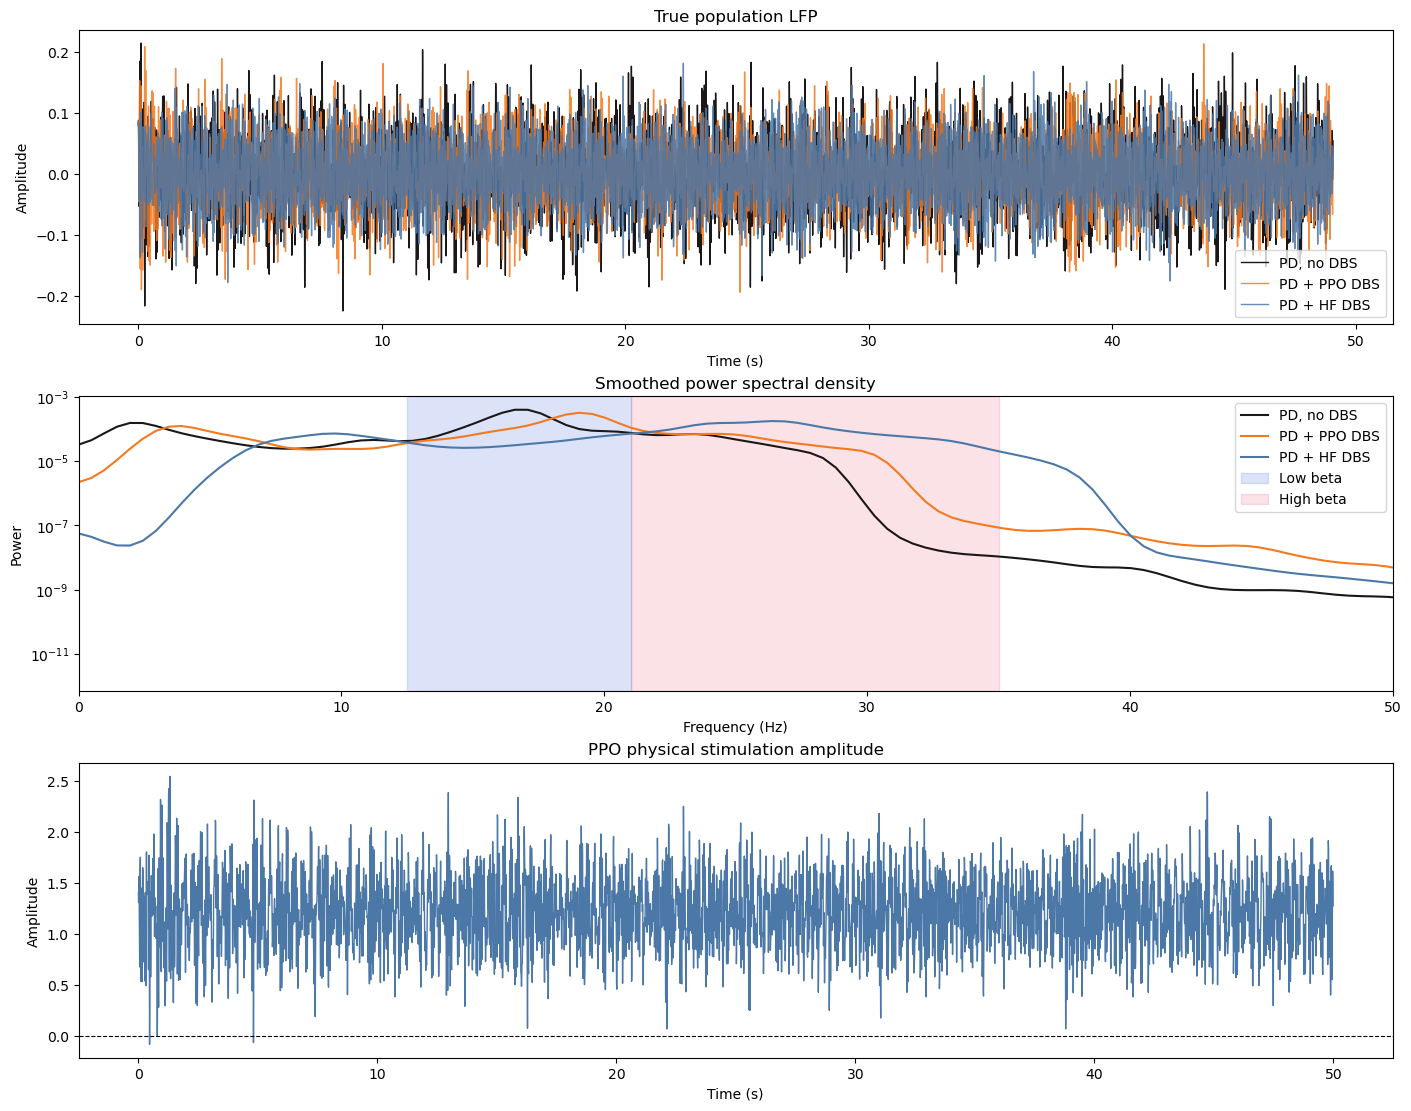

In [ ]:
dt = pd_result["dt"]
fs = 1.0 / dt
time_pd = np.arange(len(pd_result["true_lfp"])) * dt
time_ppo = np.arange(len(ppo_result["true_lfp"])) * dt
time_hf = np.arange(len(hf_result["true_lfp"])) * dt
time_sac = np.arange(len(sac_result["true_lfp"])) * dt

frequencies_pd, psd_pd = smoothed_psd(pd_result["true_lfp"], dt)
frequencies_ppo, psd_ppo = smoothed_psd(ppo_result["true_lfp"], dt)
frequencies_hf, psd_hf = smoothed_psd(hf_result["true_lfp"], dt)
frequencies_sac, psd_sac = smoothed_psd(sac_result["true_lfp"], dt)

fig, axes = plt.subplots(3, 1, figsize=(14, 11), constrained_layout=True)

axes[0].plot(time_pd, pd_result["true_lfp"], color="#1B1719", lw=1, label="PD, no DBS")
axes[0].plot(time_ppo, ppo_result["true_lfp"], color="#F47A20", lw=1, alpha=0.85, label="PD + PPO DBS")
axes[0].plot(time_hf, hf_result["true_lfp"], color="#4C78A8", lw=1, alpha=0.85, label="PD + HF DBS")
axes[0].plot(time_sac, sac_result["true_lfp"], color="#7289A3", lw=1, alpha=0.85, label="PD + SAC DBS")
axes[0].set_title("True population LFP")
axes[0].set_xlabel("Time (s)")
axes[0].set_ylabel("Amplitude")
axes[0].legend()

axes[1].semilogy(frequencies_pd, psd_pd, color="#1B1719", lw=1.5, label="PD, no DBS")
axes[1].semilogy(frequencies_ppo, psd_ppo, color="#F47A20", lw=1.5, label="PD + PPO DBS")
axes[1].semilogy(frequencies_hf, psd_hf, color="#4C78A8", lw=1.5, label="PD + HF DBS")
axes[1].semilogy(frequencies_sac, psd_sac, color="#7289A3", lw=1.5, label="PD + SAC DBS")
axes[1].axvspan(12.5, 21, color="royalblue", alpha=0.18, label="Low beta")
axes[1].axvspan(21, 35, color="crimson", alpha=0.12, label="High beta")
axes[1].set_xlim(0, 50)
axes[1].set_title("Smoothed power spectral density")
axes[1].set_xlabel("Frequency (Hz)")
axes[1].set_ylabel("Power")
axes[1].legend()

action_dt = units2sec(params["electrode_width"] + params["electrode_pause"])
time_actions = np.arange(len(ppo_result["actions"])) * action_dt
axes[2].plot(time_actions, ppo_result["actions"], color="#4C78A8", lw=1)
axes[2].axhline(0, color="black", ls="--", lw=0.8)
axes[2].set_title("PPO physical stimulation amplitude")
axes[2].set_xlabel("Time (s)")
axes[2].set_ylabel("Amplitude")

plt.show()


## Summary metrics


In [ ]:
pd_beta = beta_power(pd_result["true_lfp"], pd_result["dt"])
ppo_beta = beta_power(ppo_result["true_lfp"], ppo_result["dt"])
hf_beta = beta_power(hf_result["true_lfp"], hf_result["dt"])
sac_beta = beta_power(sac_result["true_lfp"], sac_result["dt"])

ppo_energy = float(np.abs(ppo_result["actions"]).sum())
hf_energy = float(np.abs(hf_result["actions"]).sum())
sac_energy = float(np.abs(sac_result["actions"]).sum())

summary = {
    "PD beta power": pd_beta,
    "PPO beta power": ppo_beta,
    "HF beta power": hf_beta,
    "SAC beta power": sac_beta,

    "PPO beta power (% of PD)": 100 * ppo_beta / pd_beta,
    "HF beta power (% of PD)": 100 * hf_beta / pd_beta,
    "SAC beta power (% of PD)": 100 * sac_beta / pd_beta,

    "PPO energy": ppo_energy,
    "HF energy": hf_energy,
    "SAC energy": sac_energy,
    "PPO energy (% of HF)": 100 * ppo_energy / hf_energy,
    "SAC energy (% of HF)": 100 * sac_energy / hf_energy,

    "PPO mean reward": float(np.mean(ppo_result["rewards"])),
    "HF mean reward": float(np.mean(hf_result["rewards"])),
    "SAC mean reward": float(np.mean(sac_result["rewards"])),

    "PD steps": len(pd_result["rewards"]),
    "PPO steps": len(ppo_result["rewards"]),
    "HF steps": len(hf_result["rewards"]),
    "SAC steps": len(sac_result["rewards"]),
}

summary

{'PD beta power': np.float32(0.0023545653),
 'PPO beta power': np.float32(0.0015650144),
 'HF beta power': np.float32(0.00031462766),
 'PPO beta power (% of PD)': np.float32(66.46723),
 'HF beta power (% of PD)': np.float32(13.3624525),
 'PPO energy': 6751.427827868611,
 'HF energy': 27775.0,
 'PPO energy (% of HF)': 24.307570937420742,
 'PPO mean reward': -3.0401794568490006,
 'HF mean reward': -0.8354020616873326,
 'PD steps': 5555,
 'PPO steps': 5555,
 'HF steps': 5555}